# SerpentGuard AI — Milestone 2: SAM Segmentation & Data Preprocessing Pipeline
**Group 5 · IIT Madras BS in Data Science & AI Lab (2026 T3)**  
**Author:** Vikas (Group 5) · **Team:** Jayesh Bansal (Lead), Vikas, Puneet Bajaj, Manas Rastogi  

This notebook builds directly on the outputs of the upstream milestone notebooks:
- **Reads from `03_process_dataset`**: `puneetbajajiitm/serpentguard-indian-snakes-processed` (181,231 photos across 208 active classes, `metadata.csv`, `classes.csv`).
- **Reads from `05_merge_sam_masks`**: `puneetbajajiitm/serpentguard-sam-masks` (precomputed SAM 2.1 binary masks and `mask_stats.csv`).
- **Produces**: Letterboxed 320×320 whole-photo inputs with aligned SAM masks as segmentation targets (mask-guided crops optional), tier-aware joint image+mask augmentations, and a PyTorch multi-task Dataset and class-balanced DataLoader for Milestone 3 modeling.

## 1. Dataset Paths
Finds the mounted Kaggle datasets by handle (`kagglehub` downloads them when running elsewhere) and stops if one is missing, so the pipeline never runs on stand-in data.

In [1]:
import os
import pathlib
import warnings
from typing import Dict, Tuple, List

import cv2
import kagglehub
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import albumentations as A
from albumentations.pytorch import ToTensorV2

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

PROCESSED_HANDLE = "puneetbajajiitm/serpentguard-indian-snakes-processed"
SAM_MASKS_HANDLE = "puneetbajajiitm/serpentguard-sam-masks"

PROCESSED_DIR = pathlib.Path(kagglehub.dataset_download(PROCESSED_HANDLE))
SAM_MASKS_DIR = pathlib.Path(kagglehub.dataset_download(SAM_MASKS_HANDLE))
for root, needed in [(PROCESSED_DIR, "metadata.csv"), (SAM_MASKS_DIR, "mask_stats.csv")]:
    if not (root / needed).exists():
        raise FileNotFoundError(f"{needed} not found under {root}; attach the dataset")

WORK_DIR      = pathlib.Path("/kaggle/working/preprocessed") if os.path.exists("/kaggle") else pathlib.Path("./preprocessed_output")
PREVIEW_DIR   = WORK_DIR / "previews"
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

print(f"1. Processed Dir : {PROCESSED_DIR}")
print(f"2. SAM Masks Dir : {SAM_MASKS_DIR}")
print(f"Output Directory : {WORK_DIR.resolve()}")

1. Processed Dir : /kaggle/input/datasets/puneetbajajiitm/serpentguard-indian-snakes-processed
2. SAM Masks Dir : /kaggle/input/datasets/puneetbajajiitm/serpentguard-sam-masks
Output Directory : /kaggle/working/preprocessed


## 2. Load Processed Manifest & Build Hierarchical Targets
Loads `metadata.csv` from `serpentguard-indian-snakes-processed` (produced by `03_process_dataset`, 181,231 photos) without re-running any duplicate or pHash checks. Species ids come from that dataset's `classes.csv` (`class_id`), so they match across splits; `metadata.csv` itself has no class ids. Genus and family ids are numbered over the 208 classes, and the WHO risk id maps `who_category` values `not_listed`, `2` and `1` to 0, 1 and 2. Photos in the `unknown_pool` belong to no class (`class_id = -1`) and are not used by the loaders below.

In [2]:
df = pd.read_csv(PROCESSED_DIR / "metadata.csv", dtype={"obs_id": str, "photo_id": str, "observer_id": str}, low_memory=False)
classes = pd.read_csv(PROCESSED_DIR / "classes.csv")
df = df.merge(classes[["species", "class_id"]], on="species", how="left")
df["class_id"] = df["class_id"].fillna(-1).astype(int)

# Build hierarchical target encoders over the 208 classes
genera_list   = sorted(classes["genus"].unique())
families_list = sorted(classes["family"].unique())
genus_to_id   = {g: i for i, g in enumerate(genera_list)}
family_to_id  = {f: i for i, f in enumerate(families_list)}
who_to_id     = {"not_listed": 0, "2": 1, "1": 2}

df["genus_id"]    = df["genus"].map(genus_to_id).fillna(-1).astype(int)
df["family_id"]   = df["family"].map(family_to_id).fillna(-1).astype(int)
df["who_risk_id"] = df["who_category"].astype(str).map(who_to_id)
unexpected = df.loc[df["who_risk_id"].isna(), "who_category"].unique()
if len(unexpected):
    raise ValueError(f"unexpected who_category values: {unexpected}")
df["who_risk_id"] = df["who_risk_id"].astype(int)

in_classes = df["class_id"] >= 0
print(f"Loaded manifest: {len(df):,} photos; {in_classes.sum():,} in {classes['species'].nunique()} classes, "
      f"{len(genera_list)} genera, {len(families_list)} families.")
print("Photos by split:", df["split"].value_counts().to_dict())
print("WHO risk id (photos in classes):", df.loc[in_classes, "who_risk_id"].value_counts().sort_index().to_dict())
print("Species per WHO risk id:", classes["who_category"].astype(str).map(who_to_id).value_counts().sort_index().to_dict())

Loaded manifest: 181,231 photos; 180,575 in 208 classes, 70 genera, 13 families.
Photos by split: {'train': 129241, 'val': 25639, 'test_extra': 18390, 'test': 7305, 'unknown_pool': 656}
WHO risk id (photos in classes): {0: 157613, 1: 9332, 2: 13630}
Species per WHO risk id: {0: 191, 1: 11, 2: 6}


## 3. Link SAM Masks from `serpentguard-sam-masks`
Joins `mask_stats.csv` (produced by `05_merge_sam_masks`) on `path`. Its `mask_path` is relative to the dataset's `masks/` folder. Only unflagged masks are used; flagged masks wait for the team's manual check. Photos without a usable mask (flagged, no snake found, and every validation and test photo) get a full-frame mask in the next section, so they are letterboxed whole.

In [3]:
df["abs_image_path"] = [str(PROCESSED_DIR / "data" / p) for p in df["path"]]

mask_stats = pd.read_csv(SAM_MASKS_DIR / "mask_stats.csv", usecols=["path", "mask_path", "flagged"])
df = df.merge(mask_stats, on="path", how="left")
usable_mask = df["mask_path"].fillna("").ne("") & df["flagged"].eq(False)
df["abs_mask_path"] = ""
df.loc[usable_mask, "abs_mask_path"] = [str(SAM_MASKS_DIR / "masks" / p) for p in df.loc[usable_mask, "mask_path"]]

missing_masks = sum(not os.path.exists(p) for p in df.loc[usable_mask, "abs_mask_path"])
missing_photos = sum(not os.path.exists(p) for p in df.sample(500, random_state=0)["abs_image_path"])
print(f"Usable SAM masks: {usable_mask.sum():,} of {df['split'].eq('train').sum():,} training photos "
      f"({df['flagged'].eq(True).sum():,} flagged or without a snake, left out)")
if missing_masks or missing_photos:
    raise FileNotFoundError(f"{missing_masks} mask files and {missing_photos} of 500 sampled photos are missing")

Usable SAM masks: 96,929 of 129,241 training photos (32,312 flagged or without a snake, left out)


## 4. Image Hygiene & Morphological Cleaning
`04_sam_masks` made each mask on the photo's stored pixel grid, without EXIF rotation, so photos are loaded the same way here: rotating only the photo would misalign it with its mask. The cell counts EXIF orientation tags on a sample of training photos to show what that choice affects. Morphological cleanup preserves genuine coiled snake segments while filtering isolated background specks.

In [4]:
def load_rgb(img_path: str) -> np.ndarray:
    """Loads a photo on its stored pixel grid, the grid its SAM mask was made on."""
    with Image.open(img_path) as im:
        return np.asarray(im.convert("RGB"), dtype=np.uint8)

exif_sample = df[df["split"] == "train"].sample(2000, random_state=1)["abs_image_path"]
rotated = 0
for p in exif_sample:
    with Image.open(p) as im:
        rotated += im.getexif().get(0x0112, 1) not in (0, 1)
print(f"EXIF rotation tags: {rotated} of {len(exif_sample):,} sampled training photos")

def keep_largest_snake_components(mask: np.ndarray, min_area_ratio: float = 0.015) -> np.ndarray:
    """Removes tiny isolated background artifacts while preserving coiled or occluded snake segments."""
    h, w = mask.shape[:2]
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    if num_labels <= 1:
        return np.ones((h, w), dtype=np.uint8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    max_area = areas.max()
    if max_area < (h * w * min_area_ratio):
        return np.ones((h, w), dtype=np.uint8)

    clean = np.zeros((h, w), dtype=np.uint8)
    for idx, area in enumerate(areas, start=1):
        if area >= max(0.12 * max_area, h * w * 0.008):
            clean[labels == idx] = 1
    return clean

def load_sam_segmentation_mask(rgb_img: np.ndarray, mask_path: str = "") -> Tuple[np.ndarray, List[float]]:
    """Loads precomputed SAM binary mask, cleans speckles, and extracts normalized YOLOv8-seg polygon."""
    h, w = rgb_img.shape[:2]
    binary_mask = None

    if mask_path:
        with Image.open(mask_path) as mim:
            binary_mask = (np.asarray(mim.convert("L"), dtype=np.uint8) > 127).astype(np.uint8)
        if binary_mask.shape != (h, w):
            raise ValueError(f"mask {binary_mask.shape} does not match photo {(h, w)}: {mask_path}")

    if binary_mask is None or binary_mask.sum() < 25:
        # Default full-frame mask when photo has no usable SAM pseudo-label
        binary_mask = np.ones((h, w), dtype=np.uint8)

    # Morphological closing and connected-component cleaning
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    binary_mask = keep_largest_snake_components(binary_mask)

    return binary_mask, mask_to_yolo_polygon(binary_mask)

def mask_to_yolo_polygon(binary_mask: np.ndarray, max_points: int = 64) -> List[float]:
    """Converts a binary mask into normalized YOLOv8-seg polygon coordinates [x1, y1, ...]."""
    h, w = binary_mask.shape[:2]
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return [0.05, 0.05, 0.95, 0.05, 0.95, 0.95, 0.05, 0.95]
    largest = max(contours, key=cv2.contourArea)
    epsilon = 0.002 * cv2.arcLength(largest, True)
    approx  = cv2.approxPolyDP(largest, epsilon, True).reshape(-1, 2)
    if len(approx) > max_points:
        idx = np.linspace(0, len(approx) - 1, max_points, dtype=int)
        approx = approx[idx]
    poly = []
    for x, y in approx:
        poly.extend([round(float(x) / w, 5), round(float(y) / h, 5)])
    return poly

EXIF rotation tags: 0 of 2,000 sampled training photos


## 5. Input Modes and the SAM Mask
Only training photos have SAM masks, and the phone app will not run SAM, so the model's input has to look the same in training, validation, test and on the phone. The default mode is therefore:
- **`full` (default)**: the whole photo, letterboxed to 320×320 without distortion. The SAM mask goes through the same letterbox and augmentation and is used only as the target of the segmentation head.

The mask-guided modes stay available for a Milestone 3 ablation. To be a fair comparison they need the same treatment at test time, for example a crop from the detector's box:
- **`soft_dim` (`bg_alpha=0.20`)**: keeps the snake pixels and dims the background by 80% towards neutral gray, with Gaussian edge softening.
- **`hard_mask`**: replaces every non-snake pixel with neutral gray `(124, 116, 104)`.
- **`rgbm_4ch`**: keeps the RGB photo and adds the binary mask as a 4th channel.

The mask-guided modes also crop tightly around the mask (+6% padding). Every mode keeps the aspect ratio, so slender vine snakes (*Ahaetulla*) are not distorted into stout vipers (*Daboia*).

In [5]:
IMAGENET_MEAN_RGB = (124, 116, 104)

def preprocess_with_sam_mask(
    rgb_img: np.ndarray,
    sam_mask: np.ndarray,
    target_size: int = 320,
    mode: str = "full",
    bg_alpha: float = 0.20,
    pad_ratio: float = 0.06
) -> Tuple[np.ndarray, np.ndarray]:
    """Applies the input mode, a tight crop around the SAM mask (mask-guided modes only), and 320x320 letterbox padding."""
    h, w = rgb_img.shape[:2]

    if mode in ("soft_dim", "hard_mask"):
        alpha = 0.0 if mode == "hard_mask" else bg_alpha
        soft_m = cv2.GaussianBlur(sam_mask.astype(np.float32), (5, 5), 0)[..., None]
        weight = alpha + (1.0 - alpha) * soft_m
        bg_fill = np.array(IMAGENET_MEAN_RGB, dtype=np.float32).reshape(1, 1, 3)
        proc_rgb = (rgb_img.astype(np.float32) * weight + bg_fill * (1.0 - weight)).clip(0, 255).astype(np.uint8)
    else:
        proc_rgb = rgb_img

    # Tight crop around SAM mask envelope (+6% padding), mask-guided modes only
    ys, xs = np.where(sam_mask > 0)
    if mode != "full" and len(xs) > 10 and len(ys) > 10:
        x1, x2 = int(xs.min()), int(xs.max())
        y1, y2 = int(ys.min()), int(ys.max())
        bw, bh = x2 - x1, y2 - y1
        pad_x, pad_y = int(bw * pad_ratio), int(bh * pad_ratio)
        x1, y1 = max(0, x1 - pad_x), max(0, y1 - pad_y)
        x2, y2 = min(w, x2 + pad_x), min(h, y2 + pad_y)
        crop_rgb  = proc_rgb[y1:y2, x1:x2]
        crop_mask = sam_mask[y1:y2, x1:x2]
    else:
        crop_rgb, crop_mask = proc_rgb, sam_mask

    # Aspect-ratio-preserving letterbox resize to target_size
    ch, cw = crop_rgb.shape[:2]
    scale = target_size / max(ch, cw)
    new_w, new_h = max(1, int(round(cw * scale))), max(1, int(round(ch * scale)))

    interp = cv2.INTER_AREA if scale < 1.0 else cv2.INTER_LINEAR
    res_rgb  = cv2.resize(crop_rgb,  (new_w, new_h), interpolation=interp)
    res_mask = cv2.resize(crop_mask, (new_w, new_h), interpolation=cv2.INTER_NEAREST)

    canvas_rgb  = np.full((target_size, target_size, 3), IMAGENET_MEAN_RGB, dtype=np.uint8)
    canvas_mask = np.zeros((target_size, target_size), dtype=np.uint8)

    top  = (target_size - new_h) // 2
    left = (target_size - new_w) // 2
    canvas_rgb[top:top + new_h, left:left + new_w]  = res_rgb
    canvas_mask[top:top + new_h, left:left + new_w] = res_mask

    return canvas_rgb, canvas_mask

## 6. Tier-Aware Joint `(Image + SAM Mask)` Augmentation Pipeline
Applies geometric and photometric transformations simultaneously to both the RGB image and its SAM binary mask. Tier-2 species (20–399 photos) receive stronger augmentation than Tier-1 species (≥400 photos).


In [6]:
def build_sam_augmentation_pipelines(img_size: int = 320) -> Dict[str, A.Compose]:
    norm_and_tensor = [
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ]

    tier1_aug = A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.2),
        A.Affine(scale=(0.88, 1.12), rotate=(-25, 25), translate_percent=(-0.05, 0.05), border_mode=cv2.BORDER_CONSTANT, p=0.6),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.04, p=0.5),
        A.CoarseDropout(num_holes_range=(1, 4), hole_height_range=(16, 36), hole_width_range=(16, 36), p=0.35),
        *norm_and_tensor
    ])

    tier2_aug = A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.35),
        A.Affine(scale=(0.80, 1.20), rotate=(-45, 45), translate_percent=(-0.08, 0.08), shear=(-10, 10), border_mode=cv2.BORDER_CONSTANT, p=0.8),
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.7),
        A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=25, val_shift_limit=25, p=0.5),
        A.MotionBlur(blur_limit=(3, 7), p=0.25),
        A.CoarseDropout(num_holes_range=(2, 6), hole_height_range=(20, 44), hole_width_range=(20, 44), p=0.5),
        *norm_and_tensor
    ])

    eval_aug = A.Compose([*norm_and_tensor])
    return {"tier1": tier1_aug, "tier2": tier2_aug, "eval": eval_aug}

aug_pipelines = build_sam_augmentation_pipelines(img_size=320)


## 7. PyTorch Multi-Task SAM Dataset (`SerpentGuardSAMDataset`)
Yields synchronized batches with species `class_id`, `genus_id`, `family_id`, clinical `who_risk_id`, normalized `image` tensor, and auxiliary `mask` tensor.


In [7]:
class SerpentGuardSAMDataset(Dataset):
    def __init__(
        self,
        dataframe: pd.DataFrame,
        transforms_dict: Dict[str, A.Compose],
        img_size: int = 320,
        is_train: bool = True,
        mask_mode: str = "full",
        bg_alpha: float = 0.20,
        concat_mask_channel: bool = False
    ):
        self.df = dataframe.reset_index(drop=True)
        self.transforms = transforms_dict
        self.img_size = img_size
        self.is_train = is_train
        self.mask_mode = mask_mode
        self.bg_alpha = bg_alpha
        self.concat_mask_channel = concat_mask_channel

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        row = self.df.iloc[idx]
        rgb = load_rgb(row["abs_image_path"])

        mask_p = str(row.get("abs_mask_path", ""))
        sam_mask, _ = load_sam_segmentation_mask(rgb, mask_path=mask_p)
        fg_coverage = float(sam_mask.mean())

        crop_rgb, crop_mask = preprocess_with_sam_mask(
            rgb, sam_mask, target_size=self.img_size, mode=self.mask_mode, bg_alpha=self.bg_alpha
        )

        tier_val = str(row.get("tier", "tier1"))
        pipe_key = tier_val if (self.is_train and tier_val in ["tier1", "tier2"]) else "eval"
        augmented = self.transforms[pipe_key](image=crop_rgb, mask=crop_mask)
        img_tensor  = augmented["image"]
        mask_tensor = augmented["mask"].unsqueeze(0).float()

        if self.concat_mask_channel:
            img_tensor = torch.cat([img_tensor, mask_tensor], dim=0)

        return {
            "image": img_tensor,
            "mask": mask_tensor,
            "mask_coverage": torch.tensor(fg_coverage, dtype=torch.float32),
            "class_id": torch.tensor(int(row["class_id"]), dtype=torch.long),
            "genus_id": torch.tensor(int(row["genus_id"]), dtype=torch.long),
            "family_id": torch.tensor(int(row["family_id"]), dtype=torch.long),
            "who_risk_id": torch.tensor(int(row["who_risk_id"]), dtype=torch.long),
        }

## 8. Tempered Class-Balanced Sampler & DataLoader Construction
Applies inverse square-root class frequency weighting ($1 / \sqrt{N_c}$) combined with clinical safety priority boosts:
- **WHO Category 1**: 1.60× boost
- **WHO Category 2**: 1.35× boost


In [8]:
train_df = df[df["split"] == "train"].copy().reset_index(drop=True)
val_df   = df[df["split"] == "val"].copy().reset_index(drop=True)
test_df  = df[df["split"] == "test"].copy().reset_index(drop=True)
assert (train_df["class_id"] >= 0).all() and (val_df["class_id"] >= 0).all() and (test_df["class_id"] >= 0).all()

class_counts = train_df["class_id"].value_counts().to_dict()
base_weights = train_df["class_id"].map(lambda c: 1.0 / np.sqrt(max(1, class_counts.get(c, 1))))
who_boost    = train_df["who_risk_id"].map({0: 1.0, 1: 1.35, 2: 1.60})
sample_weights = (base_weights * who_boost).values

train_sampler = WeightedRandomSampler(
    weights=torch.from_numpy(sample_weights).double(),
    num_samples=len(train_df),
    replacement=True
)

train_ds = SerpentGuardSAMDataset(train_df, aug_pipelines, img_size=320, is_train=True,  mask_mode="full")
val_ds   = SerpentGuardSAMDataset(val_df,   aug_pipelines, img_size=320, is_train=False, mask_mode="full")
test_ds  = SerpentGuardSAMDataset(test_df,  aug_pipelines, img_size=320, is_train=False, mask_mode="full")

train_loader = DataLoader(train_ds, batch_size=32, sampler=train_sampler, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train batches     : {len(train_loader):,} ({len(train_ds):,} samples)")
print(f"Validation batches: {len(val_loader):,} ({len(val_ds):,} samples)")
print(f"Test batches      : {len(test_loader):,} ({len(test_ds):,} samples)")

Train batches     : 4,039 (129,241 samples)
Validation batches: 802 (25,639 samples)
Test batches      : 229 (7,305 samples)


## 9. Visual Verification: 5-Panel Preprocessing Preview
Shows three training photos with usable masks, one per WHO risk level. This notebook is kept in a public repository with its outputs, so the preview only uses CC0 and CC BY photos and prints each photographer's credit.
1. Raw RGB photo
2. Binary SAM mask
3. YOLOv8-seg polygon contour overlay
4. Default model input: the whole photo letterboxed to 320×320 (`full`)
5. Soft-dimmed crop (320×320, `bg_alpha=0.20`), for the ablation only

                     species license                                            attribution                                                                         url
             Echis carinatus   cc-by                 (c) Kian, some rights reserved (CC BY)  https://inaturalist-open-data.s3.amazonaws.com/photos/359140312/medium.jpg
Craspedocephalus malabaricus   cc-by (c) Karthik Thrikkadeeri, some rights reserved (CC BY) https://inaturalist-open-data.s3.amazonaws.com/photos/155143754/medium.jpeg
      Protobothrops jerdonii   cc-by                 (c) Jigu, some rights reserved (CC BY)  https://inaturalist-open-data.s3.amazonaws.com/photos/507897013/medium.jpg


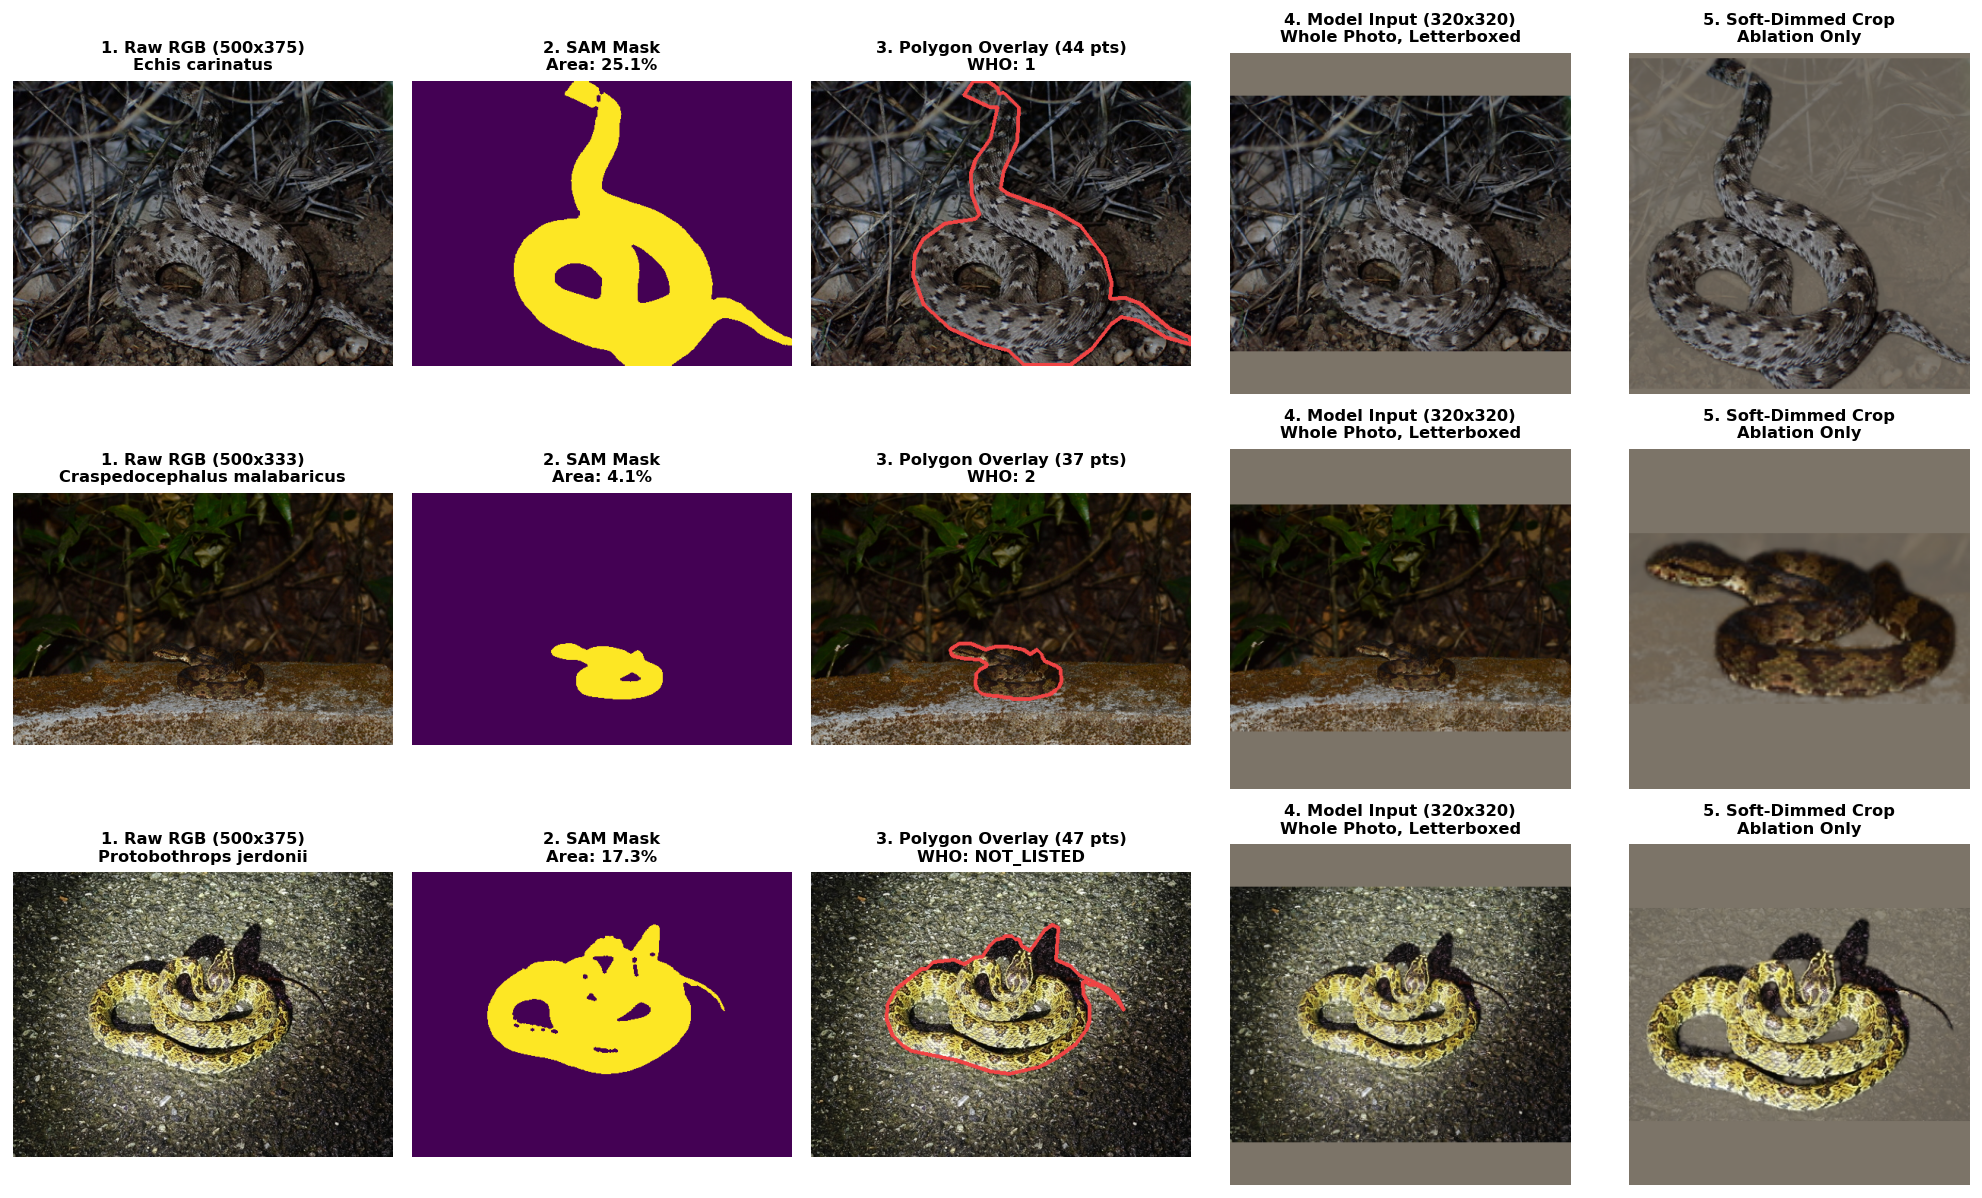

Saved 5-panel verification figure to: /kaggle/working/preprocessed/previews/sam_preprocessing_5panel.png


In [9]:
def visualize_sam_preprocessing_pipeline(
    sample_rows: pd.DataFrame,
    save_path: str = str(PREVIEW_DIR / "sam_preprocessing_5panel.png")
):
    n = len(sample_rows)
    fig, axes = plt.subplots(n, 5, figsize=(15.5, 3.1 * max(1, n)))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, (_, row) in enumerate(sample_rows.iterrows()):
        rgb = load_rgb(row["abs_image_path"])

        mask_p = str(row.get("abs_mask_path", ""))
        sam_mask, poly = load_sam_segmentation_mask(rgb, mask_path=mask_p)
        full_input, _  = preprocess_with_sam_mask(rgb, sam_mask, target_size=320, mode="full")
        soft_crop, _   = preprocess_with_sam_mask(rgb, sam_mask, target_size=320, mode="soft_dim", bg_alpha=0.20)

        # Panel 1: Raw RGB
        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title(f"1. Raw RGB ({rgb.shape[1]}x{rgb.shape[0]})\n{row['species']}", fontsize=9, fontweight="bold")

        # Panel 2: Binary SAM Mask
        axes[i, 1].imshow(sam_mask, cmap="viridis")
        src_tag = "SAM Mask" if mask_p and os.path.exists(mask_p) else "Fallback Mask"
        axes[i, 1].set_title(f"2. {src_tag}\nArea: {sam_mask.mean()*100:.1f}%", fontsize=9, fontweight="bold")

        # Panel 3: Polygon Overlay
        overlay = rgb.copy()
        pts_norm = np.array(poly).reshape(-1, 2)
        pts_px = np.column_stack([pts_norm[:, 0] * rgb.shape[1], pts_norm[:, 1] * rgb.shape[0]]).astype(np.int32)
        cv2.polylines(overlay, [pts_px], True, (239, 68, 68), thickness=3)
        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title(f"3. Polygon Overlay ({len(pts_px)} pts)\nWHO: {str(row['who_category']).upper()}", fontsize=9, fontweight="bold")

        # Panel 4: Default model input
        axes[i, 3].imshow(full_input)
        axes[i, 3].set_title("4. Model Input (320x320)\nWhole Photo, Letterboxed", fontsize=9, fontweight="bold")

        # Panel 5: Soft-Dimmed (ablation only)
        axes[i, 4].imshow(soft_crop)
        axes[i, 4].set_title("5. Soft-Dimmed Crop\nAblation Only", fontsize=9, fontweight="bold")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.savefig(save_path, bbox_inches="tight")
    plt.show()
    print(f"Saved 5-panel verification figure to: {save_path}")

PREVIEW_LICENSES = ["cc0", "cc-by"]
preview_pool = train_df[(train_df["abs_mask_path"] != "") & train_df["license"].isin(PREVIEW_LICENSES)]
sample_preview_df = preview_pool.groupby("who_risk_id").sample(1, random_state=7).sort_values("who_risk_id", ascending=False)
print(sample_preview_df[["species", "license", "attribution", "url"]].to_string(index=False))
visualize_sam_preprocessing_pipeline(sample_preview_df)

## 10. Multi-Task Batch Shape Verification & Manifest Export
Validates one batch through the PyTorch DataLoader and exports the verified manifest.


In [10]:
batch = next(iter(train_loader))
print("Verified PyTorch Multi-Task Batch Shapes:")
for k, v in batch.items():
    print(f"  - {k:<15}: shape={tuple(v.shape)} | dtype={v.dtype}")
print(f"Lowest per-image pixel spread in the batch: {batch['image'].flatten(1).std(1).min().item():.3f} (a blank image would be 0)")
print(f"Mask coverage in the batch: {batch['mask_coverage'].min().item():.2f} to {batch['mask_coverage'].max().item():.2f}")

val_batch = next(iter(val_loader))
print(f"Validation batch: images {tuple(val_batch['image'].shape)}, mask coverage {val_batch['mask_coverage'].min().item():.2f} (full frame = 1.00)")

out_manifest = WORK_DIR / "serpentguard_m2_sam_preprocessed_manifest.csv"
df["sample_weight"] = np.nan
df.loc[df["split"] == "train", "sample_weight"] = sample_weights
df.to_csv(out_manifest, index=False)
print(f"Saved preprocessed manifest ({len(df):,} rows) -> {out_manifest}")

Verified PyTorch Multi-Task Batch Shapes:
  - image          : shape=(32, 3, 320, 320) | dtype=torch.float32
  - mask           : shape=(32, 1, 320, 320) | dtype=torch.float32
  - mask_coverage  : shape=(32,) | dtype=torch.float32
  - class_id       : shape=(32,) | dtype=torch.int64
  - genus_id       : shape=(32,) | dtype=torch.int64
  - family_id      : shape=(32,) | dtype=torch.int64
  - who_risk_id    : shape=(32,) | dtype=torch.int64
Lowest per-image pixel spread in the batch: 0.461 (a blank image would be 0)
Mask coverage in the batch: 0.02 to 1.00
Validation batch: images (32, 3, 320, 320), mask coverage 1.00 (full frame = 1.00)
Saved preprocessed manifest (181,231 rows) -> /kaggle/working/preprocessed/serpentguard_m2_sam_preprocessed_manifest.csv
